# `Geocroissant` to GeoDCAT Conversion 🥐

## Introduction

<div style="display: flex; justify-content: space-between; align-items: center; gap: 24px;">
  <div>
    <p style="margin-top: 0;">This notebook performs transformation of dataset metadata from the <a href="https://github.com/mlcommons/croissant">GeoCroissant</a> JSON-LD format into the <a href="https://github.com/SEMICeu/GeoDCAT-AP">GeoDCAT-AP (v3.1.0)</a> standard. GeoDCAT-AP extends W3C DCAT to describe geospatial datasets, data series, and spatial services.</p>
  </div>
  <img src="../assets/geocr.jpg" alt="GeoCroissant" width="115" style="border-radius: 8px; flex-shrink: 0;">
</div>

### GeoCroissant to GeoDCAT Mapping

| GeoCroissant Field | GeoDCAT Field | Description |
| :--- | :--- | :--- |
| `name` / `@id` | `id` / `properties.title` | Dataset identifier and human-readable title (`dct:identifier`, `dct:title`) |
| `description` | `properties.description` | Detailed dataset description (`dct:description`) |
| `license` | `properties.license` | Dataset license URI (`dct:license` pointing to `dct:LicenseDocument`) |
| `spatialCoverage` (`Place` / `GeoShape` box) | `bbox` & `geometry` | Bounding box coordinates in WKT (`dcat:bbox` & `locn:geometry`) |
| `datePublished` / `scenes/datetime` | `properties.datetime` | ISO 8601 acquisition timestamp (`dct:issued` & `dct:temporal`) |
| `geocr:coordinateReferenceSystem` / `scenes/epsg` | `proj:epsg` | Coordinate Reference System via standard EPSG URI (`dct:conformsTo`) |
| `geocr:spatialResolution` | `properties.gsd` | Ground sample distance / spatial resolution in meters (`dcat:spatialResolutionInMeters`) |
| `geocr:spectralBandMetadata` | `eo:bands` on distributions | Spectral band names, center wavelengths (nm), and bandwidths |
| `geocr:bandConfiguration` | `band_configuration` | Total band count and ordered band names list |
| `scenes/cloud_cover` | `eo:cloud_cover` | Scene cloud cover percentage (`geocr:cloudCover`) |
| `scenes/platform` | `properties.platform` | Remote sensing satellite or platform (`geocr:platform`) |
| `citeAs` | `sci:citation` | Scientific citation and bibliographic reference (`dct:bibliographicCitation`) |
| `distribution` (`FileObject` list) | `distributions` | Distribution map with direct COG URLs, media types, and SHA-256 checksums |


In [1]:
# !pip install rdflib pyshacl rasterio numpy matplotlib

import os
import re
import json
from decimal import Decimal
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import Window
from rdflib import Graph, Namespace, URIRef, Literal, BNode
from rdflib.namespace import RDF, DCTERMS, DCAT, XSD, FOAF
from pyshacl import validate

## 1. Load GeoCroissant metadata

We load the source GeoCroissant metadata file (`sentinel2_las_vegas.json`), which documents cloud-free Sentinel-2 Level-2A imagery over Las Vegas, Nevada:

In [2]:
# Load GeoCroissant JSON-LD file
json_path = "sentinel2_las_vegas.json"
with open(json_path, "r") as f:
    gc_metadata = json.load(f)

print(f"Dataset name:        {gc_metadata.get('name')}")
print(f"Description:         {gc_metadata.get('description')}")
print(f"CRS:                 {gc_metadata.get('geocr:coordinateReferenceSystem')}")
print(f"Spatial resolution:  {gc_metadata.get('geocr:spatialResolution')}")
print(f"Spatial box:         {gc_metadata.get('spatialCoverage')}")
print(f"Distributions count: {len(gc_metadata.get('distribution', []))}")

Dataset name:        sentinel-2-las-vegas
Description:         Cloud-free Sentinel-2 Level-2A optical imagery over Las Vegas curated from Element 84 STAC API.
CRS:                 EPSG:32611
Spatial resolution:  {'@type': 'sc:QuantitativeValue', 'unitText': 'm', 'value': 10.0}
Spatial box:         {'@type': 'Place', 'geo': {'@type': 'GeoShape', 'box': '35.133016 -115.902135 36.139732 -114.668797'}}
Distributions count: 13


## 2. Convert GeoCroissant to GeoDCAT RDF

We map GeoCroissant structures into an RDF Graph (`rdflib.Graph`) compliant with the GeoDCAT-AP 3.1.0 specification

In [3]:
def geocroissant_to_geodcat(gc: dict) -> Graph:
    """Converts a GeoCroissant JSON-LD dictionary into a GeoDCAT-AP 3.1.0 compliant RDF graph."""
    g = Graph()

    # Define standard namespaces
    GSP = Namespace("http://www.opengis.net/ont/geosparql#")
    LOCN = Namespace("http://www.w3.org/ns/locn#")
    SPDX = Namespace("http://spdx.org/rdf/terms#")
    GEOCR = Namespace("http://mlcommons.org/croissant/geo/")

    g.bind("dcat", DCAT)
    g.bind("dct", DCTERMS)
    g.bind("gsp", GSP)
    g.bind("locn", LOCN)
    g.bind("spdx", SPDX)
    g.bind("xsd", XSD)
    g.bind("foaf", FOAF)
    g.bind("geocr", GEOCR)

    # 1. Extract scene record fields if available
    record = {}
    for rs in gc.get("recordSet", []):
        rs_data = rs.get("data")
        if isinstance(rs_data, dict):
            record = rs_data
            break
        elif isinstance(rs_data, list) and len(rs_data) > 0:
            record = rs_data[0]
            break

    # 2. Extract spectral band metadata
    spectral_map = {}
    for s in gc.get("geocr:spectralBandMetadata", []):
        b_name = s.get("name")
        cw = s.get("geocr:centerWavelength", {}).get("value")
        bw = s.get("geocr:bandwidth", {}).get("value")
        if b_name:
            spectral_map[b_name.upper()] = {
                "cw": cw,
                "bw": bw,
                "desc": s.get("description", ""),
            }

    # 3. Core dcat:Dataset typing and properties
    dataset_id = record.get("scenes/scene_id") or gc.get("name") or "dataset"
    dataset_uri = URIRef(f"https://example.org/dataset/{dataset_id}")

    g.add((dataset_uri, RDF.type, DCAT.Dataset))
    g.add((dataset_uri, DCTERMS.identifier, Literal(dataset_id)))
    g.add((dataset_uri, DCTERMS.title, Literal(gc.get("name", dataset_id), lang="en")))

    description = gc.get("description", "")
    if description:
        g.add((dataset_uri, DCTERMS.description, Literal(description, lang="en")))

    # License
    license_url = gc.get("license")
    if license_url:
        lic_uri = URIRef(license_url)
        g.add((lic_uri, RDF.type, DCTERMS.LicenseDocument))
        g.add((dataset_uri, DCTERMS.license, lic_uri))

    # Citation
    cite_as = gc.get("citeAs")
    if cite_as:
        g.add((dataset_uri, DCTERMS.bibliographicCitation, Literal(cite_as)))

    # Landing page
    landing_url = gc.get("url")
    if landing_url:
        page_uri = URIRef(landing_url)
        g.add((page_uri, RDF.type, FOAF.Document))
        g.add((dataset_uri, DCAT.landingPage, page_uri))

    # Keywords
    for kw in gc.get("keywords", []):
        g.add((dataset_uri, DCAT.keyword, Literal(kw, lang="en")))

    # Spatial coverage (dcat:bbox & locn:geometry as gsp:wktLiteral)
    sp_geo = gc.get("spatialCoverage", {}).get("geo", {})
    box_str = sp_geo.get("box")
    if box_str:
        coords = [float(c) for c in box_str.split()]
        min_lat, min_lon, max_lat, max_lon = coords[0], coords[1], coords[2], coords[3]
        wkt = (
            f"POLYGON(({min_lon} {min_lat}, {max_lon} {min_lat}, {max_lon} {max_lat},"
            f" {min_lon} {max_lat}, {min_lon} {min_lat}))"
        )

        loc = BNode()
        g.add((loc, RDF.type, DCTERMS.Location))
        wkt_lit = Literal(wkt, datatype=GSP.wktLiteral)
        g.add((loc, DCAT.bbox, wkt_lit))

        geom = BNode()
        g.add((geom, RDF.type, LOCN.Geometry))
        g.add((geom, RDF.type, GSP.Geometry))
        g.add((geom, LOCN.asWKT, wkt_lit))
        g.add((geom, GSP.asWKT, wkt_lit))
        g.add((loc, LOCN.geometry, geom))
        g.add((loc, GSP.hasGeometry, geom))
        g.add((dataset_uri, DCTERMS.spatial, loc))

    # Temporal coverage (dct:temporal & dct:issued)
    date_str = record.get("scenes/datetime") or gc.get("datePublished")
    if date_str:
        date_lit = Literal(
            date_str, datatype=XSD.dateTime if "T" in date_str else XSD.date
        )
        g.add((dataset_uri, DCTERMS.issued, date_lit))

        period = BNode()
        g.add((period, RDF.type, DCTERMS.PeriodOfTime))
        g.add((period, DCAT.startDate, date_lit))
        g.add((period, DCAT.endDate, date_lit))
        g.add((dataset_uri, DCTERMS.temporal, period))

    # Remote sensing scene properties
    if record.get("scenes/platform"):
        g.add((dataset_uri, GEOCR.platform, Literal(str(record["scenes/platform"]))))
    if record.get("scenes/cloud_cover") is not None:
        g.add(
            (
                dataset_uri,
                GEOCR.cloudCover,
                Literal(float(record["scenes/cloud_cover"]), datatype=XSD.float),
            )
        )

    # Coordinate Reference System (dct:conformsTo with dct:Standard)
    crs_val = record.get("scenes/epsg") or gc.get("geocr:coordinateReferenceSystem")
    if crs_val:
        epsg_match = re.search(r"(\d+)", str(crs_val))
        if epsg_match:
            epsg_code = epsg_match.group(1)
            crs_uri = URIRef(f"http://www.opengis.net/def/crs/EPSG/0/{epsg_code}")
            g.add((crs_uri, RDF.type, DCTERMS.Standard))
            g.add((crs_uri, DCTERMS.title, Literal(f"EPSG:{epsg_code}", lang="en")))
            g.add((dataset_uri, DCTERMS.conformsTo, crs_uri))

    # Spatial Resolution (dcat:spatialResolutionInMeters with xsd:decimal)
    res_val = gc.get("geocr:spatialResolution")
    if isinstance(res_val, dict) and "value" in res_val:
        g.add(
            (
                dataset_uri,
                DCAT.spatialResolutionInMeters,
                Literal(Decimal(str(res_val["value"]))),
            )
        )
    elif isinstance(res_val, (int, float)):
        g.add(
            (
                dataset_uri,
                DCAT.spatialResolutionInMeters,
                Literal(Decimal(str(res_val))),
            )
        )

    # Band configuration
    band_cfg = gc.get("geocr:bandConfiguration")
    if band_cfg:
        cfg_node = BNode()
        g.add((cfg_node, RDF.type, GEOCR.BandConfiguration))
        if "geocr:totalBands" in band_cfg:
            g.add(
                (
                    cfg_node,
                    GEOCR.totalBands,
                    Literal(int(band_cfg["geocr:totalBands"]), datatype=XSD.integer),
                )
            )
        if "geocr:bandNamesList" in band_cfg:
            g.add(
                (
                    cfg_node,
                    GEOCR.bandNamesList,
                    Literal(str(band_cfg["geocr:bandNamesList"])),
                )
            )
        g.add((dataset_uri, GEOCR.bandConfiguration, cfg_node))

    # Media type definitions
    media_uri = URIRef("https://www.iana.org/assignments/media-types/image/tiff")
    g.add((media_uri, RDF.type, DCTERMS.MediaType))
    g.add((media_uri, RDF.type, DCTERMS.MediaTypeOrExtent))

    algo_uri = SPDX.checksumAlgorithm_sha256
    g.add((algo_uri, RDF.type, SPDX.ChecksumAlgorithm))

    # Distributions (cr:FileObject -> dcat:Distribution)
    for dist in gc.get("distribution", []):
        dist_id = dist.get("@id", dist.get("name", "distribution"))
        dist_uri = URIRef(f"https://example.org/distribution/{dist_id}")

        g.add((dist_uri, RDF.type, DCAT.Distribution))
        name = dist.get("name", dist_id)
        g.add((dist_uri, DCTERMS.title, Literal(name, lang="en")))
        if dist.get("description"):
            g.add(
                (dist_uri, DCTERMS.description, Literal(dist["description"], lang="en"))
            )

        content_url = dist.get("contentUrl")
        if content_url:
            url_ref = URIRef(content_url)
            g.add((dist_uri, DCAT.accessURL, url_ref))
            g.add((dist_uri, DCAT.downloadURL, url_ref))

        g.add((dist_uri, DCAT.mediaType, media_uri))
        g.add((dist_uri, DCTERMS.format, media_uri))

        # SHA-256 Checksum (spdx:Checksum)
        sha256_val = dist.get("sha256")
        if sha256_val:
            chk = BNode()
            g.add((chk, RDF.type, SPDX.Checksum))
            g.add((chk, SPDX.algorithm, algo_uri))
            g.add(
                (chk, SPDX.checksumValue, Literal(sha256_val, datatype=XSD.hexBinary))
            )
            g.add((dist_uri, SPDX.checksum, chk))

        # Attach spectral band details
        clean_band = name.replace(".tif", "").upper()
        if clean_band in spectral_map:
            sm = spectral_map[clean_band]
            if sm["cw"]:
                g.add(
                    (
                        dist_uri,
                        GEOCR.centerWavelength,
                        Literal(float(sm["cw"]), datatype=XSD.float),
                    )
                )
            if sm["bw"]:
                g.add(
                    (
                        dist_uri,
                        GEOCR.bandwidth,
                        Literal(float(sm["bw"]), datatype=XSD.float),
                    )
                )

        g.add((dataset_uri, DCAT.distribution, dist_uri))

    return g


# Execute conversion
geodcat_graph = geocroissant_to_geodcat(gc_metadata)
print(f"Constructed GeoDCAT RDF graph with {len(geodcat_graph)} triples.")

Constructed GeoDCAT RDF graph with 220 triples.


## 3. Serialize GeoDCAT metadata to Turtle and JSON-LD

We serialize the RDF graph into standard Turtle (`sentinel2_geodcat.ttl`) and JSON-LD (`sentinel2_geodcat.jsonld`):

In [4]:
# Serialize to Turtle (.ttl)
ttl_path = "sentinel2_geodcat.ttl"
geodcat_graph.serialize(destination=ttl_path, format="turtle")
print(f"Serialized Turtle RDF:  {ttl_path} ({os.path.getsize(ttl_path)} bytes)")

# Serialize to JSON-LD (.jsonld)
jsonld_path = "sentinel2_geodcat.jsonld"
geodcat_graph.serialize(destination=jsonld_path, format="json-ld", indent=2)
print(f"Serialized JSON-LD RDF: {jsonld_path} ({os.path.getsize(jsonld_path)} bytes)")

# Display a snippet of the generated Turtle metadata
print("\n--- Turtle Metadata Snippet (first 30 lines) ---")
with open(ttl_path, "r") as f:
    for i, line in enumerate(f):
        if i >= 30:
            break
        print(line.rstrip())

Serialized Turtle RDF:  sentinel2_geodcat.ttl (15446 bytes)
Serialized JSON-LD RDF: sentinel2_geodcat.jsonld (33010 bytes)

--- Turtle Metadata Snippet (first 30 lines) ---
@prefix dcat: <http://www.w3.org/ns/dcat#> .
@prefix dct: <http://purl.org/dc/terms/> .
@prefix foaf: <http://xmlns.com/foaf/0.1/> .
@prefix geocr: <http://mlcommons.org/croissant/geo/> .
@prefix gsp: <http://www.opengis.net/ont/geosparql#> .
@prefix locn: <http://www.w3.org/ns/locn#> .
@prefix spdx: <http://spdx.org/rdf/terms#> .
@prefix xsd: <http://www.w3.org/2001/XMLSchema#> .

<https://example.org/dataset/S2A_11SPV_20230907_0_L2A> a dcat:Dataset ;
    geocr:bandConfiguration [ a geocr:BandConfiguration ;
            geocr:bandNamesList "['B01', 'B02', 'B03', 'B04', 'B05', 'B06', 'B07', 'B08', 'B8A', 'B09', 'B11', 'B12']" ;
            geocr:totalBands 12 ] ;
    geocr:cloudCover "0.016788"^^xsd:float ;
    geocr:platform "sentinel-2a" ;
    dct:bibliographicCitation """@article{CopernicusSentinel2,
  title={Cop

## 4. Validate GeoDCAT metadata with SHACL

In [5]:
# Validate the Turtle & JSON-LD file directly using the pySHACL CLI validator
!pyshacl -s geodcat_ap_shacl.ttl -df json-ld -i rdfs sentinel2_geodcat.jsonld
!pyshacl -s geodcat_ap_shacl.ttl -df turtle -i rdfs sentinel2_geodcat.ttl

Validation Report
Conforms: True
Validation Report
Conforms: True


## 5. Load and query GeoDCAT metadata via SPARQL

We query the RDF graph using SPARQL to extract dataset attributes, platform, cloud cover, spatial bounds, and distribution access endpoints:

In [6]:
# 1. Query Dataset Summary & Remote Sensing Properties
query_dataset = """
PREFIX dcat: <http://www.w3.org/ns/dcat#>
PREFIX dct: <http://purl.org/dc/terms/>
PREFIX gsp: <http://www.opengis.net/ont/geosparql#>
PREFIX geocr: <http://mlcommons.org/croissant/geo/>

SELECT ?id ?title ?res ?crs ?startDate ?platform ?cloudCover ?bbox WHERE {
    ?ds a dcat:Dataset ;
        dct:identifier ?id ;
        dct:title ?title ;
        dcat:spatialResolutionInMeters ?res ;
        dct:conformsTo ?crs ;
        dct:temporal [ dcat:startDate ?startDate ] ;
        dct:spatial [ dcat:bbox ?bbox ] .
    OPTIONAL { ?ds geocr:platform ?platform }
    OPTIONAL { ?ds geocr:cloudCover ?cloudCover }
}
"""

print("SPARQL Query: Dataset Summary")
for row in geodcat_graph.query(query_dataset):
    print(f"Identifier:         {row.id}")
    print(f"Title:              {row.title}")
    print(f"Platform:           {row.platform}")
    print(f"Cloud Cover:        {row.cloudCover}")
    print(f"Spatial Resolution: {row.res} m")
    print(f"Conforms To (CRS):  {row.crs}")
    print(f"Acquisition Date:   {row.startDate}")
    print(f"Bounding Box (WKT): {row.bbox}")

# 2. Query Distributions with Spectral Metadata
query_distributions = """
PREFIX dcat: <http://www.w3.org/ns/dcat#>
PREFIX dct: <http://purl.org/dc/terms/>
PREFIX spdx: <http://spdx.org/rdf/terms#>
PREFIX geocr: <http://mlcommons.org/croissant/geo/>

SELECT ?title ?cw ?bw ?accessURL ?checksum WHERE {
    ?ds a dcat:Dataset ;
        dcat:distribution ?dist .
    ?dist dct:title ?title ;
          dcat:accessURL ?accessURL .
    OPTIONAL { ?dist geocr:centerWavelength ?cw }
    OPTIONAL { ?dist geocr:bandwidth ?bw }
    OPTIONAL { ?dist spdx:checksum [ spdx:checksumValue ?checksum ] . }
}
ORDER BY ?title
"""

print("SPARQL Query: Distributions (First 6 Bands)")
rows = list(geodcat_graph.query(query_distributions))
for row in rows[:6]:
    cw_str = f"{row.cw} nm" if row.cw else "N/A"
    bw_str = f"{row.bw} nm" if row.bw else "N/A"
    chk = str(row.checksum)[:14] + "..." if row.checksum else "N/A"
    print(
        f"{row.title:<9} | CW: {cw_str:<8} | BW: {bw_str:<7} | Checksum: {chk:<17} |"
        f" URL: {row.accessURL}"
    )
print(f"({len(rows)} total distributions available)")

SPARQL Query: Dataset Summary
Identifier:         S2A_11SPV_20230907_0_L2A
Title:              sentinel-2-las-vegas
Platform:           sentinel-2a
Cloud Cover:        0.016788
Spatial Resolution: 10.0 m
Conforms To (CRS):  http://www.opengis.net/def/crs/EPSG/0/32611
Acquisition Date:   2023-09-07T18:34:32.933000+00:00
Bounding Box (WKT): POLYGON((-115.902135 35.133016, -114.668797 35.133016, -114.668797 36.139732, -115.902135 36.139732, -115.902135 35.133016))
SPARQL Query: Distributions (First 6 Bands)
B01.tif   | CW: 443.0 nm | BW: 27.0 nm | Checksum: 0f9ee6981faed1... | URL: https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/11/S/PV/2023/9/S2A_11SPV_20230907_0_L2A/B01.tif
B02.tif   | CW: 490.0 nm | BW: 98.0 nm | Checksum: cddcd7c6225e84... | URL: https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/11/S/PV/2023/9/S2A_11SPV_20230907_0_L2A/B02.tif
B03.tif   | CW: 560.0 nm | BW: 45.0 nm | Checksum: a36fc6318c81a6... | URL: https://sentinel-cogs.s3.u

## 6. Visualize True Color (RGB) and False Color Infrared (CIR) from GeoDCAT Assets

Using the distribution URLs resolved from the GeoDCAT SPARQL query, we stream an 800x800 window over Las Vegas using `rasterio` and render True Color (RGB: B04, B03, B02) and False Color Infrared (CIR: B08, B04, B03) composites:

Resolved distribution URLs from GeoDCAT SPARQL:
  Blue: https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/11/S/PV/2023/9/S2A_11SPV_20230907_0_L2A/B02.tif
  Green: https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/11/S/PV/2023/9/S2A_11SPV_20230907_0_L2A/B03.tif
  Red: https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/11/S/PV/2023/9/S2A_11SPV_20230907_0_L2A/B04.tif
  NIR: https://sentinel-cogs.s3.us-west-2.amazonaws.com/sentinel-s2-l2a-cogs/11/S/PV/2023/9/S2A_11SPV_20230907_0_L2A/B08.tif
Successfully streamed bands from GeoDCAT distributions: ['Blue', 'Green', 'Red', 'NIR']


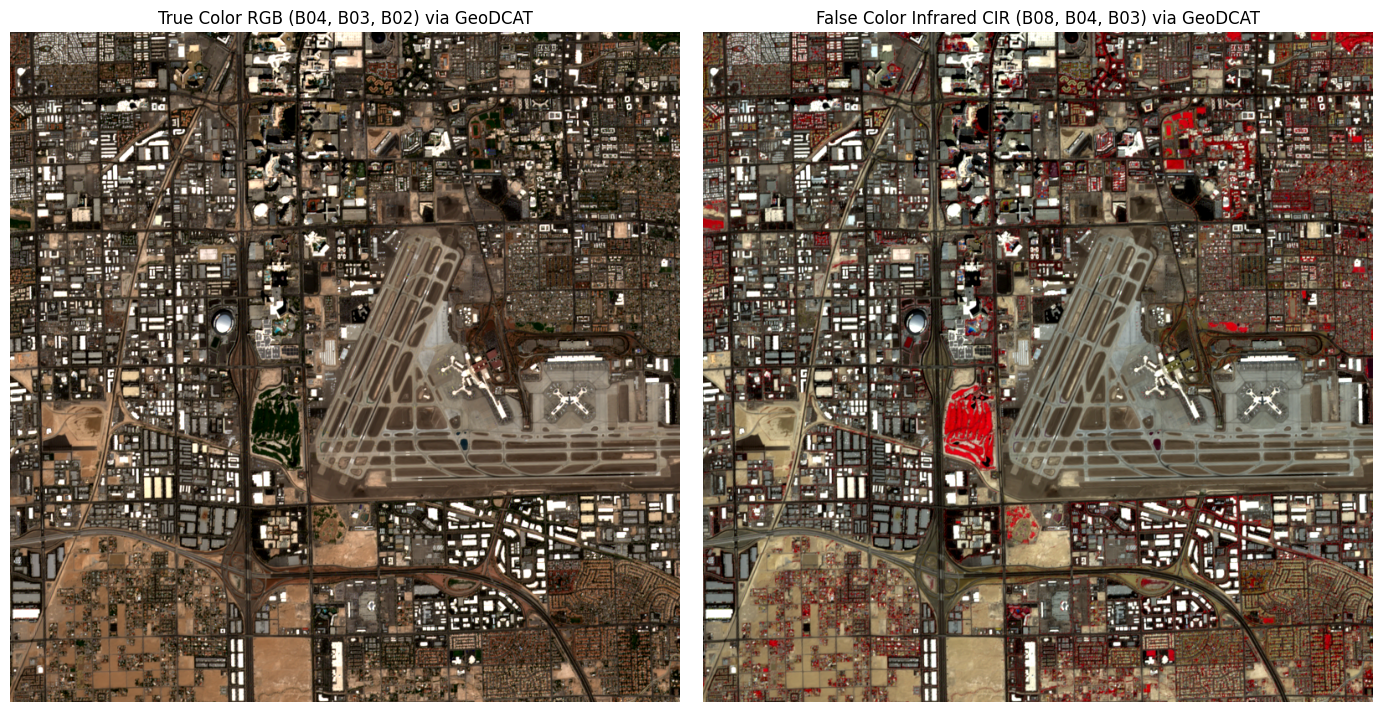

In [7]:
# Map band names from the SPARQL query results
band_map = {"Blue": "B02.tif", "Green": "B03.tif", "Red": "B04.tif", "NIR": "B08.tif"}

# Resolve access URLs directly from the SPARQL distribution query
query_urls = {}
for row in geodcat_graph.query(query_distributions):
    for band_key, file_name in band_map.items():
        if str(row.title) == file_name:
            query_urls[band_key] = str(row.accessURL)

print("Resolved distribution URLs from GeoDCAT SPARQL:")
for k, u in query_urls.items():
    print(f"  {k}: {u}")

# Stream 800x800 window over Las Vegas from Cloud-Optimized GeoTIFFs
win = Window(col_off=6100, row_off=100, width=800, height=800)
streamed_bands = {}

with rasterio.Env(AWS_NO_SIGN_REQUEST="YES"):
    for band_name, url in query_urls.items():
        with rasterio.open(url) as src:
            # Sentinel-2 L2A surface reflectance values are scaled by 10,000
            streamed_bands[band_name] = (
                src.read(1, window=win).astype(np.float32) / 10000.0
            )

print(
    "Successfully streamed bands from GeoDCAT distributions:",
    list(streamed_bands.keys()),
)

# Stack bands into composite matrices
rgb = np.dstack([
    streamed_bands["Red"], streamed_bands["Green"], streamed_bands["Blue"]
])
cir = np.dstack([streamed_bands["NIR"], streamed_bands["Red"], streamed_bands["Green"]])

# Apply 2nd-to-98th percentile stretch for optical clarity
rgb_stretched = (
    np.clip(
        (rgb - np.percentile(rgb, 2))
        / (np.percentile(rgb, 98) - np.percentile(rgb, 2)),
        0.0,
        1.0,
    )
    ** 0.85
)

cir_stretched = (
    np.clip(
        (cir - np.percentile(cir, 2))
        / (np.percentile(cir, 98) - np.percentile(cir, 2)),
        0.0,
        1.0,
    )
    ** 0.85
)

# Plot True Color and False Color Infrared composites
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(rgb_stretched)
axes[0].set_title("True Color RGB (B04, B03, B02) via GeoDCAT", fontsize=12)
axes[0].axis("off")

axes[1].imshow(cir_stretched)
axes[1].set_title("False Color Infrared CIR (B08, B04, B03) via GeoDCAT", fontsize=12)
axes[1].axis("off")

plt.tight_layout()
plt.show()